# Chapitre 11 - Cours 3 : nombre d'unités, weight decay et chiffres manuscrits

Ce notebook reproduit les deux exemples des sections 11.6 et 11.7 du livre :

1. les **données simulées** « somme de sigmoïdes » et « radiale » : erreur de test en fonction du
   nombre d'unités cachées et du paramètre de weight decay (figures 11.6, 11.7 et 11.8) ;
2. les **chiffres manuscrits** (codes postaux) : architectures du tableau 11.1, ajustement des
   réseaux entièrement connectés Net-1 et Net-2 sur un petit échantillon et courbes de
   performance au fil des époques (figure 11.11).

Il se termine par la discussion de la section 11.8 (forces et limites des réseaux).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch11_reseaux import MLP, n_weights, one_hot, sigmoid

## 1. Données simulées (section 11.6)

On simule deux modèles additifs $Y = f(X) + \varepsilon$ :

$$
\begin{aligned}
\text{somme de sigmoïdes : }\quad Y &= \sigma(a_1^T X) + \sigma(a_2^T X) + \varepsilon_1, \qquad p = 2,\ a_1 = (3,3)^T,\ a_2 = (3,-3)^T ;\\
\text{radial : }\quad Y &= \prod_{m=1}^{10} \phi(X_m) + \varepsilon_2, \qquad p = 10,\ \phi(t) = (2\pi)^{-1/2} e^{-t^2/2}.
\end{aligned}
$$

Les $X_j$ sont des gaussiennes centrées réduites indépendantes et les bruits sont gaussiens, de
variance choisie pour que le **rapport signal sur bruit**

$$\frac{\mathrm{Var}\big(\mathbb E(Y\mid X)\big)}{\mathrm{Var}\big(Y - \mathbb E(Y \mid X)\big)} = \frac{\mathrm{Var}(f(X))}{\mathrm{Var}(\varepsilon)} \qquad \text{(éq. (11.18))}$$

vaille 4 dans les deux cas. On tire $N = 100$ observations d'apprentissage et $10\,000$ de test.

Pour le modèle radial, la variance de $f$ se calcule exactement. Par indépendance des $X_m$,
$\mathbb E f(X) = \prod_m \mathbb E\phi(X_m) = \big(\mathbb E\phi(X_1)\big)^{10}$ et
$\mathbb E f(X)^2 = \big(\mathbb E\phi(X_1)^2\big)^{10}$. Or, pour $X_1 \sim \mathcal N(0,1)$,

$$\mathbb E\,\phi(X_1) = \int \phi(t)^2\,dt = \frac{1}{2\pi}\int e^{-t^2} dt = \frac{\sqrt\pi}{2\pi} = \frac{1}{2\sqrt\pi},
\qquad \mathbb E\,\phi(X_1)^2 = \int \phi(t)^3 dt = \frac{1}{(2\pi)^{3/2}} \sqrt{\frac{2\pi}{3}} = \frac{1}{2\pi\sqrt 3},$$

(en utilisant $\int e^{-ct^2}dt = \sqrt{\pi/c}$), d'où
$\mathrm{Var} f(X) = (2\pi\sqrt3)^{-10} - (2\sqrt\pi)^{-20}$.

In [2]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])

def f_sigmoides(X):
    return sigmoid(X @ a1) + sigmoid(X @ a2)

def f_radiale(X):
    return np.prod(np.exp(-X ** 2 / 2) / np.sqrt(2 * np.pi), axis=1)

var_rad = (2 * np.pi * np.sqrt(3)) ** -10 - (2 * np.sqrt(np.pi)) ** -20
rng = np.random.RandomState(0)
print("Var f radiale : exacte = %.4e, Monte-Carlo = %.4e"
      % (var_rad, np.var(f_radiale(rng.randn(1_000_000, 10)))))

Var f radiale : exacte = 3.2730e-11, Monte-Carlo = 3.2572e-11


In [3]:
def simuler(f, p, var_f, rng, N=100, N_test=10_000):
    sigma2 = var_f / 4                                   # RSB = 4
    X, Xt = rng.randn(N, p), rng.randn(N_test, p)
    y = f(X) + np.sqrt(sigma2) * rng.randn(N)
    yt = f(Xt) + np.sqrt(sigma2) * rng.randn(N_test)
    return X, y, Xt, yt, sigma2

rng = np.random.RandomState(1)
var_sig = np.var(f_sigmoides(rng.randn(1_000_000, 2)))
sim = {"Somme de sigmoïdes": simuler(f_sigmoides, 2, var_sig, rng),
       "Radial": simuler(f_radiale, 10, var_rad, rng)}

On ajuste, sur l'**unique** échantillon d'apprentissage, des réseaux à $M = 0, 1, \dots, 10$ unités
cachées, pour **10 tirages** des poids initiaux, et l'on rapporte l'erreur de test
$\mathbb E_{\text{test}}(Y - \hat f(X))^2$ **divisée par l'erreur de Bayes** $\sigma^2 = \mathrm{Var}(\varepsilon)$
(rappel : en régression quadratique, l'erreur de Bayes est la variance du bruit, atteinte par
$f$ elle-même). Le modèle à $M = 0$ unité est la régression linéaire par moindres carrés.

Détails de mise en œuvre :

* optimisation par L-BFGS (au plus 1000 itérations), poids initiaux uniformes sur $[-0{,}7 ; 0{,}7]$ ;
* la fonction radiale prend des valeurs minuscules (de l'ordre de $10^{-5}$) : on **standardise**
  la réponse avant l'ajustement (puis on revient à l'échelle d'origine), faute de quoi le
  weight decay n'aurait aucun sens.

In [4]:
def erreurs_relatives(nom, M, lam, n_starts=10):
    X, y, Xt, yt, sigma2 = sim[nom]
    mu, sd = (y.mean(), y.std()) if nom == "Radial" else (0.0, 1.0)
    out = []
    for seed in range(n_starts):
        net = MLP(n_hidden=M, weight_decay=lam, random_state=seed)
        net.fit(X, (y - mu) / sd, max_iter=1000)
        pred = mu + sd * net.predict(Xt)[:, 0]
        out.append(np.mean((yt - pred) ** 2) / sigma2)
        if M == 0:                 # modèle linéaire : un seul départ suffit (critère convexe)
            out = out * n_starts
            break
    return out

Certains départs donnent des erreurs énormes (le réseau extrapole très mal loin des données) ;
comme dans le livre, on **tronque** l'axe vertical, et l'on indique au-dessus de chaque boîte le
nombre de valeurs hors cadre.

In [5]:
def boites(ax, res, positions, ymax, ymin=None):
    """Boîtes à moustaches avec axe tronqué à ymax (valeurs hors cadre comptées)."""
    ax.boxplot(res, positions=positions, widths=0.6, medianprops=dict(color=ORANGE),
               flierprops=dict(markersize=3))
    for x, r in zip(positions, res):
        n_out = int(np.sum(np.asarray(r) > ymax))
        if n_out:
            ax.text(x, ymax * 0.97, "↑%d" % n_out, ha="center", va="top", fontsize=8, color=COLORS[7])
    ax.set_ylim(ymin if ymin is not None else 0.9, ymax)

In [6]:
Ms = list(range(11))
fig116 = {nom: [erreurs_relatives(nom, M, 0.0005) for M in Ms] for nom in sim}

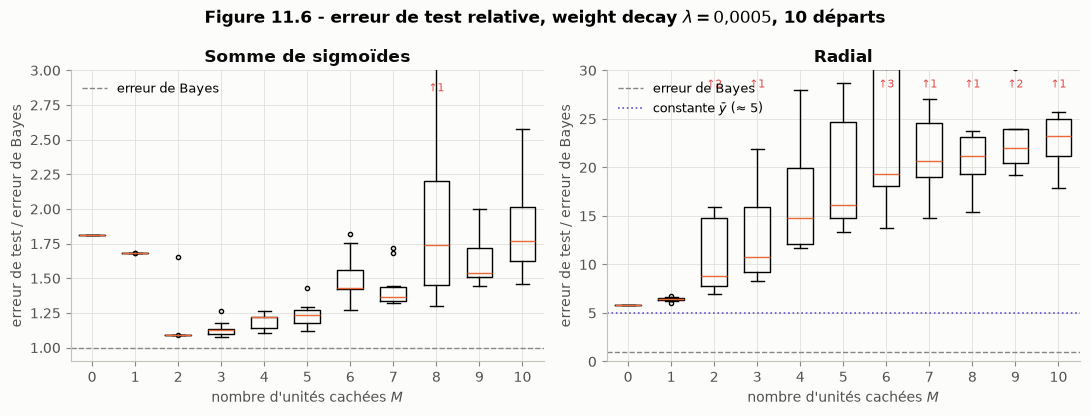

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nom, res) in zip(axes, fig116.items()):
    boites(ax, res, Ms, ymax=3.0 if nom != "Radial" else 30.0, ymin=0.9 if nom != "Radial" else 0)
    ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
    ax.set_xlabel("nombre d'unités cachées $M$")
    ax.set_ylabel("erreur de test / erreur de Bayes")
    ax.set_title(nom)
    ax.legend()
axes[1].axhline(5, ls=":", color=COLORS[6], lw=1.2, label="constante $\\bar y$ (≈ 5)")
axes[1].legend()
fig.suptitle(r"Figure 11.6 - erreur de test relative, weight decay $\lambda = 0{,}0005$, 10 départs",
             fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
for nom, res in fig116.items():
    med = [np.median(r) for r in res]
    print("%-18s médianes : %s" % (nom, np.round(med, 2)))

Somme de sigmoïdes médianes : [1.81 1.68 1.09 1.13 1.22 1.23 1.43 1.36 1.74 1.54 1.77]
Radial             médianes : [ 5.79  6.44  8.81 10.75 14.81 16.15 19.29 20.62 21.2  21.96 23.2 ]


**Somme de sigmoïdes (à gauche).** Le réseau est parfaitement adapté à ce modèle : avec
$M = 2$ unités, il contient la vraie fonction, et l'erreur est proche de celle de Bayes. Au-delà,
le **sur-ajustement** s'installe vite : avec 10 unités et une régularisation faible, certains
départs font moins bien que le modèle linéaire ($M = 0$). Avec un faible nombre d'unités, la
variabilité entre départs rappelle l'importance d'essayer **plusieurs** poids initiaux.

**Radial (à droite).** Une fonction radiale est, en un sens, la plus difficile pour un réseau :
elle est à symétrie sphérique, **sans direction privilégiée**, alors que chaque unité cachée
exploite une direction $\alpha_m$. L'erreur reste très au-dessus de celle de Bayes ; la
constante $\bar y$ obtient une erreur relative d'environ $1 + \mathrm{RSB} = 5$, et les réseaux
font de plus en plus **mal** que la moyenne quand $M$ augmente (noter l'échelle verticale).

### Weight decay nul ou fort (figure 11.7)

Le panneau de gauche suggère qu'il faut davantage de régularisation quand $M$ augmente. On
reprend l'expérience sur la somme de sigmoïdes sans weight decay ($\lambda = 0$) puis avec un
weight decay fort ($\lambda = 0{,}1$).

In [9]:
fig117 = {lam: [erreurs_relatives("Somme de sigmoïdes", M, lam) for M in Ms] for lam in [0.0, 0.1]}

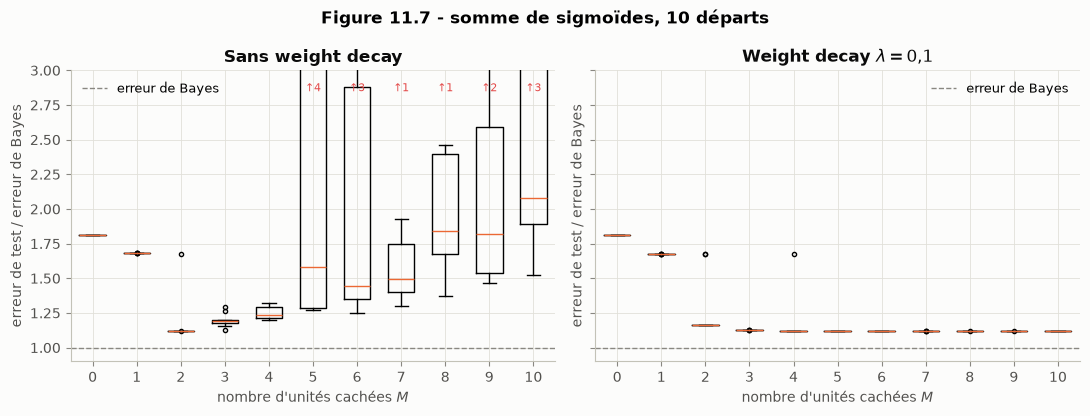

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (lam, res) in zip(axes, fig117.items()):
    boites(ax, res, Ms, ymax=3.0)
    ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
    ax.set_xlabel("nombre d'unités cachées $M$")
    ax.set_ylabel("erreur de test / erreur de Bayes")
    ax.set_title("Sans weight decay" if lam == 0 else r"Weight decay $\lambda = 0{,}1$")
    ax.legend()
fig.suptitle("Figure 11.7 - somme de sigmoïdes, 10 départs", fontweight="bold")
plt.tight_layout()
plt.show()

Sans weight decay, le sur-ajustement est encore plus marqué quand $M$ grandit. Avec
$\lambda = 0{,}1$, les résultats sont bons **pour tous les nombres d'unités** à partir de 2, sans
sur-ajustement visible quand $M$ augmente, et avec une variabilité entre départs bien plus
faible : la pénalité rend le problème d'optimisation mieux posé.

### Choix de $\lambda$ à $M$ fixé (figure 11.8)

Fixons maintenant $M = 10$ unités et faisons varier $\lambda$ entre 0 et 0,14.

In [11]:
lams = np.round(np.arange(0, 0.15, 0.01), 2)
fig118 = [erreurs_relatives("Somme de sigmoïdes", 10, lam) for lam in lams]

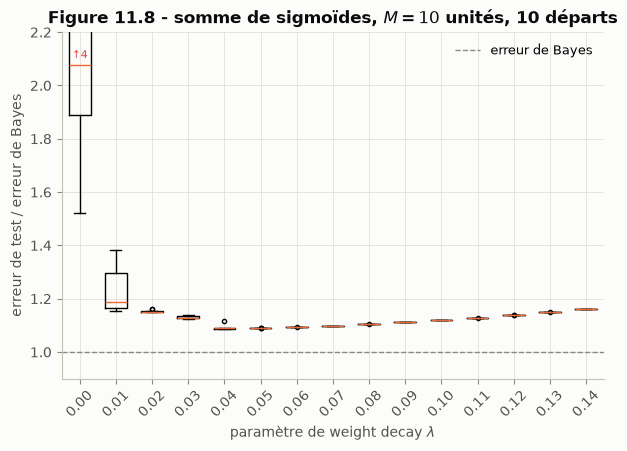

In [12]:
fig, ax = plt.subplots()
boites(ax, fig118, np.arange(len(lams)), ymax=2.2)
ax.set_xticks(np.arange(len(lams)), ["%.2f" % l for l in lams], rotation=45)
ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
ax.set_xlabel(r"paramètre de weight decay $\lambda$")
ax.set_ylabel("erreur de test / erreur de Bayes")
ax.set_title("Figure 11.8 - somme de sigmoïdes, $M = 10$ unités, 10 départs")
ax.legend()
plt.show()

In [13]:
med = np.array([np.median(r) for r in fig118])
print("lambda de médiane minimale : %.2f (médiane %.3f)" % (lams[np.argmin(med)], med.min()))

lambda de médiane minimale : 0.04 (médiane 1.088)


Sans pénalité, l'erreur est grande et très variable ; dès $\lambda \approx 0{,}02$, elle tombe près de
l'erreur de Bayes et la courbe devient très **plate** : toute valeur entre 0,03 et 0,14 convient
(le livre trouve un optimum vers 0,1 ; la position exacte dépend de l'échantillon simulé).

> **À retenir.** Il y a deux paramètres de complexité : le weight decay $\lambda$ et le nombre
> d'unités $M$. Une stratégie raisonnable consiste à fixer l'un au niveau le **moins contraint**
> (ici $M = 10$ unités) pour que le modèle soit assez riche, et à choisir l'autre ($\lambda$) par
> validation croisée. La comparaison des figures 11.7 (gauche) et 11.8 montre que l'erreur est
> moins sensible à $\lambda$ qu'à $M$, ce qui rend la validation croisée de $\lambda$ préférable.

## 2. Les chiffres manuscrits (section 11.7)

Il s'agit de reconnaître des chiffres manuscrits numérisés à partir d'enveloppes : chaque image
est un tableau $16 \times 16$ de niveaux de gris (dans $[-1, 1]$), soit $p = 256$ entrées, et il y a
$K = 10$ classes. La figure 11.9 en montre quelques exemples.

In [14]:
X_tr, y_tr = datasets.load_zip("train")
X_te, y_te = datasets.load_zip("test")
print("apprentissage :", X_tr.shape, " test :", X_te.shape)

apprentissage : (7291, 256)  test : (2007, 256)


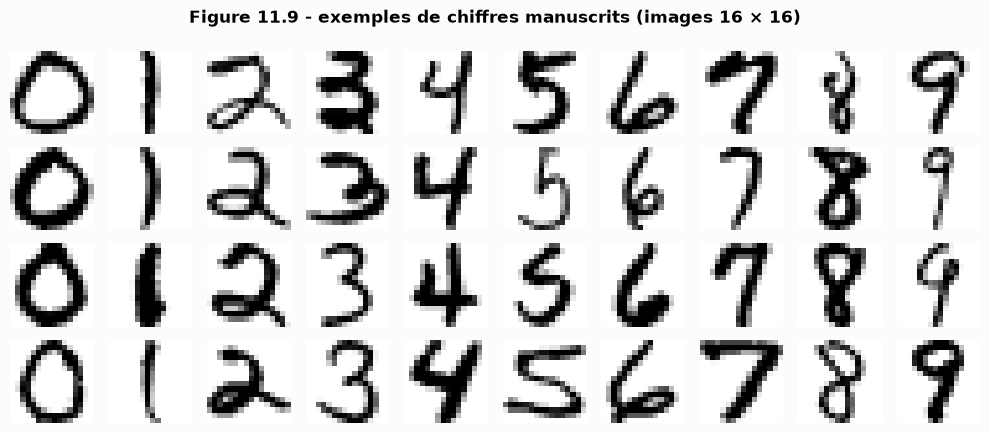

In [15]:
rng = np.random.RandomState(0)
fig, axes = plt.subplots(4, 10, figsize=(10, 4.4))
for k in range(10):
    idx = rng.choice(np.where(y_tr == k)[0], 4, replace=False)
    for r in range(4):
        axes[r, k].imshow(-X_tr[idx[r]].reshape(16, 16), cmap="gray", vmin=-1, vmax=1)
        axes[r, k].axis("off")
fig.suptitle("Figure 11.9 - exemples de chiffres manuscrits (images 16 × 16)", fontweight="bold")
plt.tight_layout()
plt.show()

### Les cinq architectures du livre (figure 11.10, tableau 11.1)

Le Cun (1989) a ajusté cinq réseaux à **320** chiffres d'apprentissage (160 de test) :

* **Net-1** : pas de couche cachée, quasiment la régression logistique multinomiale ;
* **Net-2** : une couche cachée de 12 unités **entièrement connectées** ;
* **Net-3** : deux couches cachées **localement connectées** : chaque unité de la première couche
  (grille $8\times8$) ne voit qu'un carré $3\times3$ de pixels, chaque unité de la seconde (grille
  $4\times4$) un carré $5\times5$ de la première couche ;
* **Net-4** : comme Net-3, mais la première couche comporte deux cartes $8\times8$ dont les unités
  **partagent les mêmes 9 poids** (chacune garde sa constante) : chaque carte calcule le même
  motif à tous les endroits de l'image, c'est une **convolution** ;
* **Net-5** : comme Net-4, avec en plus quatre cartes $4\times4$ à poids partagés dans la seconde
  couche, chaque unité voyant un carré $5\times5$ des deux cartes de la première couche.

On distingue le nombre de **liaisons** (connexions) et le nombre de **poids** libres : le partage
de poids réduit le second sans réduire le premier. Recalculons le tableau 11.1 (chaque unité
reçoit aussi une constante).

In [16]:
def couche(n_unites, n_entrees, partage=None):
    """(liaisons, poids) d'une couche ; partage = nb de cartes si les poids sont partagés."""
    liaisons = n_unites * (n_entrees + 1)
    if partage is None:
        return liaisons, liaisons
    unites_par_carte = n_unites // partage
    return liaisons, partage * (n_entrees + unites_par_carte)   # poids partagés + constantes

archis = {
    "Net-1 : sans couche cachée": [couche(10, 256)],
    "Net-2 : 12 unités cachées": [couche(12, 256), couche(10, 12)],
    "Net-3 : connexions locales": [couche(64, 9), couche(16, 25), couche(10, 16)],
    "Net-4 : partage (1 niveau)": [couche(128, 9, partage=2), couche(16, 50), couche(10, 16)],
    "Net-5 : partage (2 niveaux)": [couche(128, 9, partage=2), couche(64, 50, partage=4), couche(10, 64)],
}
livre = {"Net-1": 80.0, "Net-2": 87.0, "Net-3": 88.5, "Net-4": 94.0, "Net-5": 98.4}
print("%-30s %9s %8s %12s" % ("architecture", "liaisons", "poids", "% correct (livre)"))
for nom, cs in archis.items():
    print("%-30s %9d %8d %12.1f" % (nom, sum(c[0] for c in cs), sum(c[1] for c in cs), livre[nom[:5]]))

architecture                    liaisons    poids % correct (livre)
Net-1 : sans couche cachée          2570     2570         80.0
Net-2 : 12 unités cachées           3214     3214         87.0
Net-3 : connexions locales          1226     1226         88.5
Net-4 : partage (1 niveau)          2266     1132         94.0
Net-5 : partage (2 niveaux)         5194     1060         98.4


On retrouve exactement les nombres du tableau 11.1. Net-5, avec **moins** de poids que Net-1, atteint
98,4 % de bonnes classifications contre 87 % pour le réseau « standard » Net-2 : les contraintes
(connexions locales, poids partagés) traduisent une connaissance du problème - un trait
caractéristique d'écriture peut apparaître n'importe où dans l'image.

Nous reproduisons ci-dessous les deux réseaux **entièrement connectés** Net-1 et Net-2 avec notre
implémentation (une couche cachée au plus) ; les réseaux à connexions locales demanderaient deux
couches cachées et une gestion des poids partagés que notre module ne couvre pas.

### Net-1 et Net-2 sur un échantillon de 320 chiffres

Comme dans le livre, on utilise un **petit** échantillon d'apprentissage : 320 chiffres (32 par
classe) tirés au hasard dans les 7291 chiffres d'apprentissage. Le test se fait sur les **2007**
chiffres de test complets (et non sur les 160 chiffres de Le Cun, qui ne sont pas disponibles) :
les pourcentages ne sont donc pas directement comparables à ceux du livre.

Comme Le Cun, on utilise des **sorties sigmoïdes** et l'**erreur quadratique**, avec un
apprentissage **en ligne** (une observation à la fois), sur 30 époques. Les poids initiaux sont
petits (uniformes sur $[-0{,}05 ; 0{,}05]$) car il y a 256 entrées : avec $[-0{,}7 ; 0{,}7]$, les
$A_{mi}$ seraient d'emblée très grands et les sigmoïdes saturées.

In [17]:
rng = np.random.RandomState(0)
idx320 = np.concatenate([rng.choice(np.where(y_tr == k)[0], 32, replace=False) for k in range(10)])
X320, y320 = X_tr[idx320], y_tr[idx320]
Y320 = one_hot(y320, 10)

In [18]:
courbes = {}
for nom, M, lr in [("Net-1", 0, 0.02), ("Net-2", 12, 0.3)]:
    acc_test, acc_app = [], []

    def suivi(net, epoch):
        acc_test.append(100 * np.mean(net.predict_class(X_te) == y_te))
        acc_app.append(100 * np.mean(net.predict_class(X320) == y320))

    net = MLP(n_hidden=M, output="sigmoid", loss="squared", init_scale=0.05, random_state=0)
    net.fit(X320, Y320, method="sgd", batch_size=1, lr=lr, n_epochs=30, callback=suivi)
    courbes[nom] = (net, acc_app, acc_test)
    print("%s : %4d poids, %% correct apprentissage = %.1f, test = %.1f"
          % (nom, n_weights(256, M, 10), acc_app[-1], acc_test[-1]))

Net-1 : 2570 poids, % correct apprentissage = 98.8, test = 85.0


Net-2 : 3214 poids, % correct apprentissage = 99.7, test = 85.2


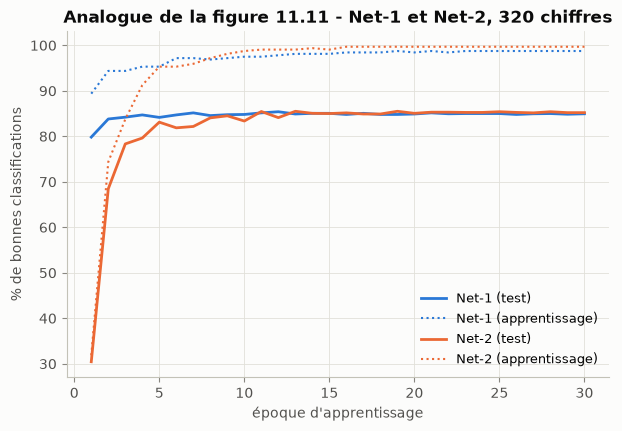

In [19]:
fig, ax = plt.subplots()
for c, (nom, (net, acc_app, acc_test)) in zip(COLORS, courbes.items()):
    ep = np.arange(1, 31)
    ax.plot(ep, acc_test, color=c, label="%s (test)" % nom)
    ax.plot(ep, acc_app, ":", color=c, lw=1.5, label="%s (apprentissage)" % nom)
ax.set_xlabel("époque d'apprentissage")
ax.set_ylabel("% de bonnes classifications")
ax.set_title("Analogue de la figure 11.11 - Net-1 et Net-2, 320 chiffres")
ax.legend()
plt.show()

Comme dans le livre, l'erreur d'**apprentissage** devient presque nulle : il y a bien plus de
paramètres (2570 ou 3214) que d'observations (320). La performance en test se stabilise après
une dizaine d'époques. Sur ce petit échantillon et notre ensemble de test, le gain de la couche
cachée est modeste : un réseau entièrement connecté n'exploite aucune structure de l'image, et
avec seulement 320 exemples il ne peut guère apprendre plus qu'une frontière presque linéaire.

Quelles caractéristiques les 12 unités cachées de Net-2 ont-elles extraites ? Chaque unité $m$
calcule $\sigma(\alpha_{0m} + \alpha_m^T x)$ : on peut représenter le vecteur $\alpha_m \in \mathbb{R}^{256}$
comme une image $16\times16$ (rouge : poids positifs, bleu : négatifs). C'est le genre de
diagramme utilisé pour tenter d'interpréter un réseau (section 11.8).

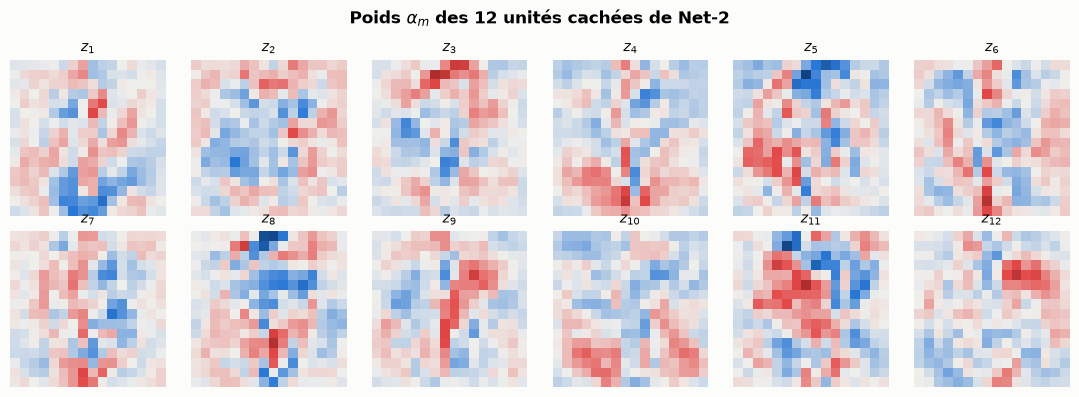

In [20]:
alpha = courbes["Net-2"][0].params_["alpha"][:, 1:]
vmax = np.abs(alpha).max()
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for m, ax in enumerate(axes.ravel()):
    ax.imshow(alpha[m].reshape(16, 16), cmap=DIV, vmin=-vmax, vmax=vmax)
    ax.set_title("$z_{%d}$" % (m + 1), fontsize=10)
    ax.axis("off")
fig.suptitle("Poids $\\alpha_m$ des 12 unités cachées de Net-2", fontweight="bold")
plt.tight_layout()
plt.show()

Les motifs sont diffus et difficiles à interpréter : chaque unité combine de nombreux pixels, et
les solutions ne sont pas identifiables (une autre base du même sous-espace donnerait presque les
mêmes prédictions).

### Avec plus de données et une régularisation

Pour compléter, ajustons des réseaux à sortie softmax et entropie croisée, avec weight decay,
par L-BFGS, sur 320 puis 1000 chiffres d'apprentissage, et un réseau plus large ($M = 40$). Le
paramètre $\lambda$ est choisi sur une petite grille par **validation** sur 1000 autres chiffres
de l'ensemble d'apprentissage (on ne touche pas à l'ensemble de test pour ce choix).

In [21]:
rng = np.random.RandomState(1)
reste = np.setdiff1d(np.arange(len(y_tr)), idx320)
perm = rng.permutation(reste)
idx_val, idx1000 = perm[:1000], perm[1000:2000]
X_val, y_val = X_tr[idx_val], y_tr[idx_val]

def ajuster(Xa, ya, M, lam, seed=0):
    net = MLP(n_hidden=M, output="softmax", loss="cross_entropy", weight_decay=lam,
              init_scale=0.05, random_state=seed)
    return net.fit(Xa, one_hot(ya, 10), max_iter=400)

In [22]:
resultats = []
for n_app, (Xa, ya) in [(320, (X320, y320)), (1000, (X_tr[idx1000], y_tr[idx1000]))]:
    for M in [0, 12, 40]:
        best = None
        for lam in [0.1, 1.0, 10.0, 100.0]:
            net = ajuster(Xa, ya, M, lam)
            acc_val = np.mean(net.predict_class(X_val) == y_val)
            if best is None or acc_val > best[0]:
                best = (acc_val, lam, net)
        acc_test = 100 * np.mean(best[2].predict_class(X_te) == y_te)
        resultats.append((n_app, M, best[1], 100 * best[0], acc_test))
        print("N = %4d, M = %2d : lambda retenu = %4.1f, %% correct validation = %.1f, test = %.1f"
              % resultats[-1])

N =  320, M =  0 : lambda retenu = 10.0, % correct validation = 90.9, test = 85.6


N =  320, M = 12 : lambda retenu =  1.0, % correct validation = 89.7, test = 85.2


N =  320, M = 40 : lambda retenu =  0.1, % correct validation = 91.1, test = 85.7


N = 1000, M =  0 : lambda retenu = 10.0, % correct validation = 92.6, test = 88.8


N = 1000, M = 12 : lambda retenu =  1.0, % correct validation = 92.7, test = 88.6


N = 1000, M = 40 : lambda retenu =  0.1, % correct validation = 93.2, test = 89.2


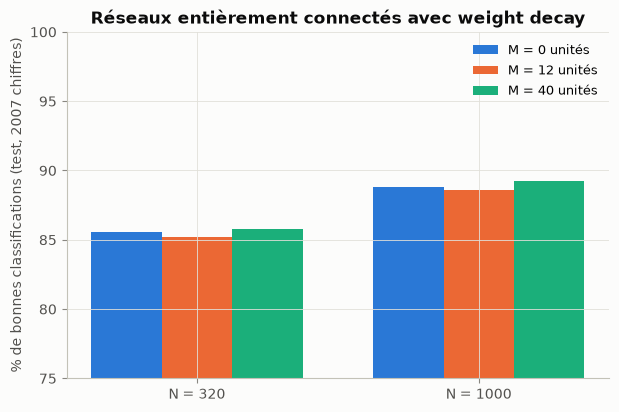

In [23]:
fig, ax = plt.subplots()
largeur = 0.25
for j, M in enumerate([0, 12, 40]):
    vals = [r[4] for r in resultats if r[1] == M]
    ax.bar(np.arange(2) + (j - 1) * largeur, vals, width=largeur, color=COLORS[j],
           label="M = %d unités" % M)
ax.set_xticks([0, 1], ["N = 320", "N = 1000"])
ax.set_ylim(75, 100)
ax.set_ylabel("% de bonnes classifications (test, 2007 chiffres)")
ax.set_title("Réseaux entièrement connectés avec weight decay")
ax.legend()
plt.show()